In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
from google.colab import files

uploaded = files.upload()

Saving student_dropout_behavior_dataset.csv to student_dropout_behavior_dataset.csv


In [3]:
df = pd.read_csv("student_dropout_behavior_dataset.csv")

print("Ukuran dataset:", df.shape)
print("\nLima data pertama:")
display(df.head())

Ukuran dataset: (300, 16)

Lima data pertama:


,student_id,name,age,gender,quiz1_marks,quiz2_marks,quiz3_marks,total_assignments,assignments_submitted,midterm_marks,final_marks,previous_gpa,total_lectures,lectures_attended,total_lab_sessions,labs_attended
0,1,Kristina Vaughan,19,Male,8.0,5.7,7.4,5,NaN,30.0,36.5,2.57,12,4,6,1
1,2,Rodney Daniels,21,Male,10.0,7.9,4.1,5,NaN,25.4,33.0,2.40,12,1,6,5
2,3,Jose Nash,19,Female,7.5,1.2,0.3,5,NaN,14.4,24.8,2.99,12,0,6,0
3,4,Nicole Martin,21,Male,5.2,2.5,9.9,5,NaN,17.7,41.0,1.68,12,9,6,0
4,5,Shelby Smith,21,Female,5.9,6.3,2.0,5,NaN,23.8,31.0,2.53,12,7,6,4


In [4]:
print("Jumlah data kosong setiap kolom:")
print(df.isnull().sum())

print("\nInformasi dataset:")
df.info()

Jumlah data kosong setiap kolom:
student_id                 0
name                       0
age                        0
gender                     0
quiz1_marks                0
quiz2_marks                0
quiz3_marks                0
total_assignments          0
assignments_submitted    300
midterm_marks              0
final_marks                0
previous_gpa               0
total_lectures             0
lectures_attended          0
total_lab_sessions         0
labs_attended              0
dtype: int64

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             300 non-null    int64  
 1   name                   300 non-null    object 
 2   age                    300 non-null    int64  
 3   gender                 300 non-null    object 
 4   quiz1_marks            300 non-null    float64
 

In [5]:
fitur_nilai = [
    "quiz1_marks",
    "quiz2_marks",
    "quiz3_marks",
    "midterm_marks",
    "final_marks",
    "previous_gpa"
]

df["lecture_attendance_pct"] = (
    df["lectures_attended"]
    / df["total_lectures"].replace(0, float("nan")) * 100
).fillna(0)

df["lab_attendance_pct"] = (
    df["labs_attended"]
    / df["total_lab_sessions"].replace(0, float("nan")) * 100
).fillna(0)

fitur = fitur_nilai + [
    "lecture_attendance_pct",
    "lab_attendance_pct"
]

X = df[fitur].apply(pd.to_numeric, errors="coerce")

print("Fitur yang digunakan:")
print(fitur)

display(X.head())

Fitur yang digunakan:
['quiz1_marks', 'quiz2_marks', 'quiz3_marks', 'midterm_marks', 'final_marks', 'previous_gpa', 'lecture_attendance_pct', 'lab_attendance_pct']


,quiz1_marks,quiz2_marks,quiz3_marks,midterm_marks,final_marks,previous_gpa,lecture_attendance_pct,lab_attendance_pct
0,8.0,5.7,7.4,30.0,36.5,2.57,33.333333,16.666667
1,10.0,7.9,4.1,25.4,33.0,2.40,8.333333,83.333333
2,7.5,1.2,0.3,14.4,24.8,2.99,0.000000,0.000000
3,5.2,2.5,9.9,17.7,41.0,1.68,75.000000,0.000000
4,5.9,6.3,2.0,23.8,31.0,2.53,58.333333,66.666667


In [6]:
X = X.fillna(X.median())

print("Jumlah data kosong setelah penanganan:")
print(X.isnull().sum())

display(X.head())

Jumlah data kosong setelah penanganan:
quiz1_marks               0
quiz2_marks               0
quiz3_marks               0
midterm_marks             0
final_marks               0
previous_gpa              0
lecture_attendance_pct    0
lab_attendance_pct        0
dtype: int64


,quiz1_marks,quiz2_marks,quiz3_marks,midterm_marks,final_marks,previous_gpa,lecture_attendance_pct,lab_attendance_pct
0,8.0,5.7,7.4,30.0,36.5,2.57,33.333333,16.666667
1,10.0,7.9,4.1,25.4,33.0,2.40,8.333333,83.333333
2,7.5,1.2,0.3,14.4,24.8,2.99,0.000000,0.000000
3,5.2,2.5,9.9,17.7,41.0,1.68,75.000000,0.000000
4,5.9,6.3,2.0,23.8,31.0,2.53,58.333333,66.666667


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardisasi berhasil.")
print("Ukuran data setelah standardisasi:", X_scaled.shape)

Standardisasi berhasil.
Ukuran data setelah standardisasi: (300, 8)


In [8]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Proses clustering selesai.")

Proses clustering selesai.


In [9]:
print("Jumlah mahasiswa dalam setiap cluster:")

print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)

Jumlah mahasiswa dalam setiap cluster:
Cluster
0     80
1    114
2    106
Name: count, dtype: int64


In [10]:
ringkasan = df.groupby("Cluster")[fitur].mean().round(2)

print("Rata-rata fitur setiap cluster:")
display(ringkasan)

Rata-rata fitur setiap cluster:


,quiz1_marks,quiz2_marks,quiz3_marks,midterm_marks,final_marks,previous_gpa,lecture_attendance_pct,lab_attendance_pct
Cluster,,,,,,,,
0,7.35,4.48,4.31,22.28,23.79,2.80,53.75,37.50
1,7.90,5.89,5.81,19.14,42.43,2.91,23.17,60.96
2,6.48,6.89,5.98,19.11,42.19,2.70,76.34,52.83


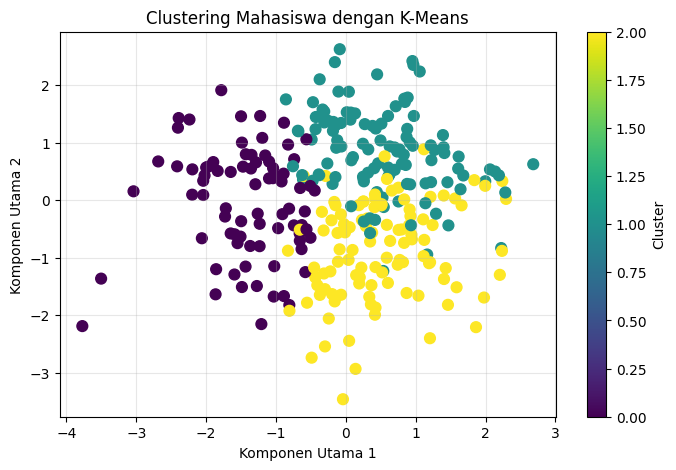

In [11]:
pca = PCA(n_components=2)

hasil_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    hasil_pca[:, 0],
    hasil_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.title("Clustering Mahasiswa dengan K-Means")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.show()

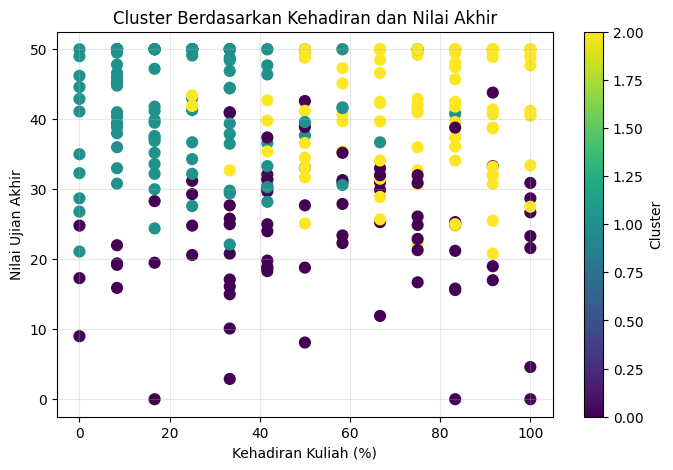

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["lecture_attendance_pct"],
    df["final_marks"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Kehadiran Kuliah (%)")
plt.ylabel("Nilai Ujian Akhir")
plt.title("Cluster Berdasarkan Kehadiran dan Nilai Akhir")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.show()

In [13]:
df.to_csv("hasil_clustering_mahasiswa.csv", index=False)

print("Hasil berhasil disimpan ke hasil_clustering_mahasiswa.csv")

Hasil berhasil disimpan ke hasil_clustering_mahasiswa.csv


In [14]:
from google.colab import files

files.download("hasil_clustering_mahasiswa.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>